## Praktikum 2
##### Erweiterte Operationen auf Gesichtern

In diesem Praktikum betrachten wir weitere Operationen auf Gesichtern und trainieren erste kleine Netzwerke zur Gesichtserkennung.

[Alpha-Compositing](https://en.wikipedia.org/wiki/Alpha_compositing)

<div style="padding: 10px; border-left: 5px solid #B777FA; background-color: #5C18FA; border-radius: 4px">
  🐍 Bitte nutzen Sie die virtuelle Umgebung: <b>DLACV_2526</b>
</div>

In [1]:
# imports
import cv2
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from utils.dataPath import DATA_PATH
%matplotlib inline

In [ ]:
# matplotlib-Einstellungen
matplotlib.rcParams['figure.figsize'] = (6.0,6.0)
matplotlib.rcParams['image.cmap'] = 'gray'

<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 1.5:</b><br>
  • Lesen Sie das Bild <code>data/images/puppets.png</code> <b>mit Alpha-Kanal</b> ein und geben es im Notebook aus.<br>
  • Brechen Sie das Bild in die einzelnen Kanäle (<b><span style="color: red">R</span>,<span style="color: green">G</span>,<span style="color: cyan">B</span> und <span style="color: magenta">A</span></b>) auf.<br>
  • Erzeugen Sie ein RGB-Bild aus den Kanälen (kein Alpha).<br>
  • Erzeugen Sie ein AAA-Bild aus den Kanälen (alle Dimensionen = Alpha).
</div>
<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #66611F; 
    border-radius: 4px; 
    margin-top: 5px;
">
💡 <i><b>Hinweis 1:</b></i> Überprüfen Sie das Format und die Kanäle, in denen das Bild eingelesen wird.<br>Sollte das Bild nicht richtig aussehen, ist möglicherweise die Reihenfolge der Farbkanäle falsch.<br>
💡 <i><b>Hinweis 2:</b></i> Nutzen Sie zum Aufbrechen und Zusammenfügen der Kanäle jeweils eine einzige <code>cv2</code>-Funktion.
</div>

(1056, 1500, 4)


Text(0.5, 1.0, 'Blue')

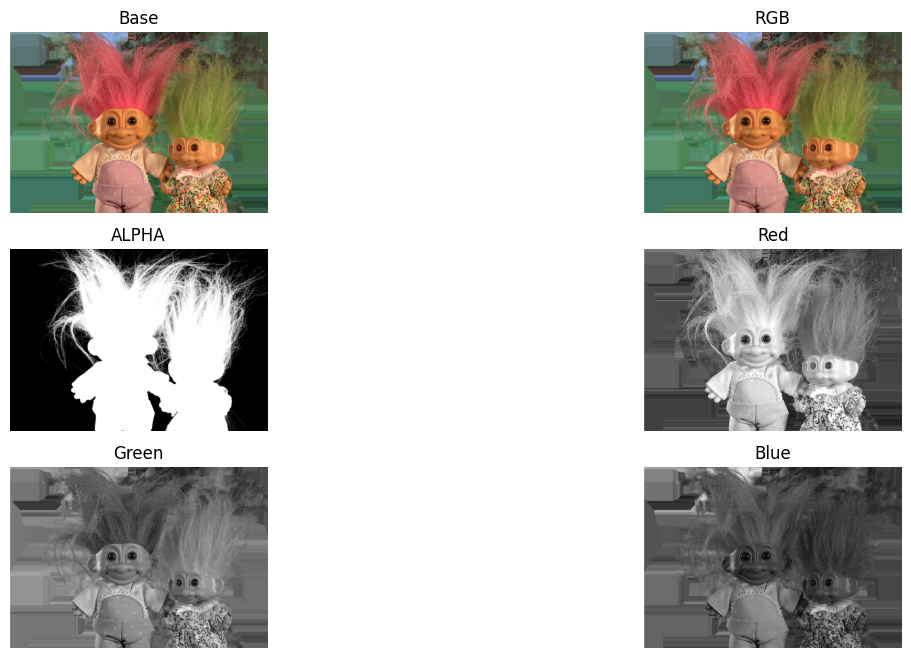

In [22]:
img = cv2.imread("data/images/puppets.png", -1)
print(img.shape)
img_b, img_g, img_r, img_a = cv2.split(img)

img_rgb = cv2.merge((img_b, img_g, img_r))
img_AAA = cv2.merge((img_a, img_a, img_a))

fig, axes = plt.subplots(3, 2, figsize=(15, 8))

axes[0,0].imshow(cv2.cvtColor(img, cv2.COLOR_RGB2BGR))
axes[0,0].axis('off')
axes[0,0].set_title('Base')

axes[0,1].imshow(cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR))
axes[0,1].axis('off')
axes[0,1].set_title('RGB')

axes[1,0].imshow(cv2.cvtColor(img_AAA, cv2.COLOR_BGR2RGB))
axes[1,0].axis('off')
axes[1,0].set_title('ALPHA')

axes[1,1].imshow(cv2.cvtColor(img_r, cv2.COLOR_BGR2RGB))
axes[1,1].axis('off')
axes[1,1].set_title('Red')

axes[2,0].imshow(cv2.cvtColor(img_g, cv2.COLOR_BGR2RGB))
axes[2,0].axis('off')
axes[2,0].set_title('Green')

axes[2,1].imshow(cv2.cvtColor(img_b, cv2.COLOR_BGR2RGB))
axes[2,1].axis('off')
axes[2,1].set_title('Blue')

<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 1.6:</b><br>
  • Lesen Sie das Bild <code>data/images/beach.jpg</code> ein und geben es im Notebook aus.
</div>
<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #66611F; 
    border-radius: 4px; 
    margin-top: 5px;
">
💡 <i><b>Hinweis:</b></i> Überprüfen Sie das Format und die Kanäle, in denen das Bild eingelesen wird.<br>Sollte das Bild nicht richtig aussehen, ist möglicherweise die Reihenfolge der Farbkanäle falsch.
</div>

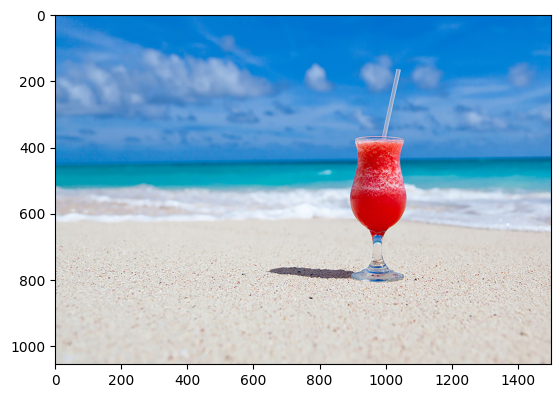

In [25]:
img_beach =cv2.imread("data/images/beach.jpg")
plt.imshow(cv2.cvtColor(img_beach, cv2.COLOR_RGB2BGR))

<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 1.7:</b><br>
  • Führen Sie ein Alpha-Blending entsprechend der Vorlesung durch. Die Puppen sollen dabei am Strand erscheinen.
</div>
<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #66611F;
    border-radius: 4px; 
    margin-top: 5px;
">
💡 <i><b>Hinweis:</b></i> Achten Sie auf das Dateiformat der Bilder und welche Formate und Wertebereiche die einzelnen Funktionen erwarten.
</div>

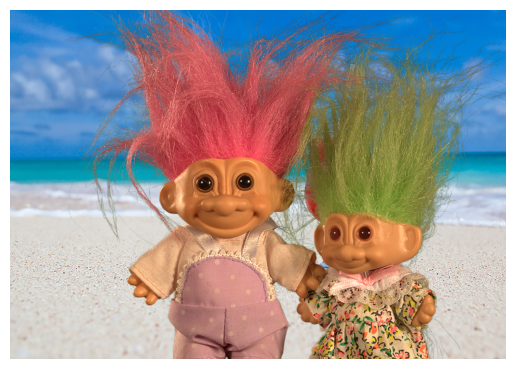

In [30]:
import utils.faceBlendCommon as fbc
outImage = cv2.cvtColor(fbc.alphaBlend(img_AAA,img_rgb,img_beach),cv2.COLOR_RGB2BGR)

# Bild anzeigen
plt.imshow(outImage)
plt.axis('off')
plt.show()

<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 1.8:</b><br>
  • Lesen Sie die Bilder <code>data/images/airplane.jpg</code> und <code>data/images/sky.jpg</code> ein und geben diese im Notebook aus.
</div>
<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #66611F; 
    border-radius: 4px; 
    margin-top: 5px;
">
💡 <i><b>Hinweis:</b></i> Überprüfen Sie das Format und die Kanäle, in denen das Bild eingelesen wird.<br>Sollte das Bild nicht richtig aussehen, ist möglicherweise die Reihenfolge der Farbkanäle falsch.
</div>

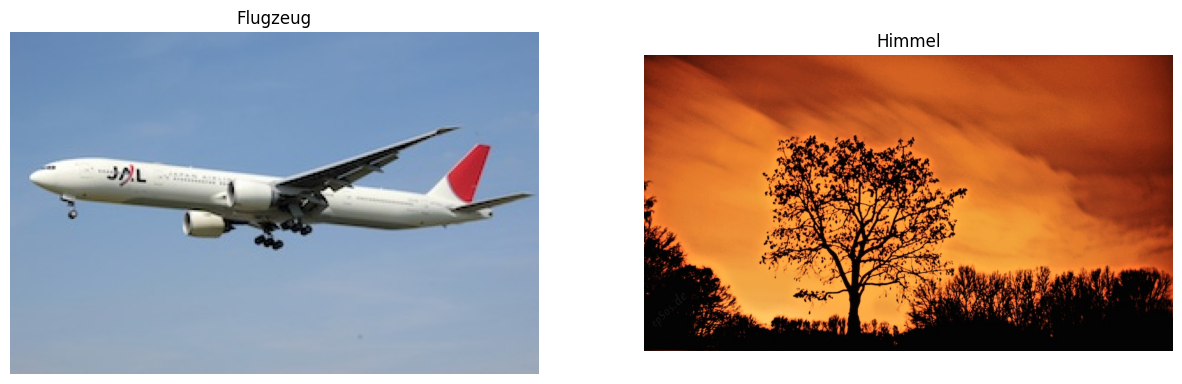

In [33]:
# Bilder einlesen und in RGB konvertieren
src = cv2.cvtColor(cv2.imread("data/images/airplane.jpg"),cv2.COLOR_RGB2BGR)
img_sky = cv2.cvtColor(cv2.imread("data/images/sky.jpg"),cv2.COLOR_RGB2BGR)

# Anzeigen
fig, axes = plt.subplots(1, 2, figsize=(15, 8))

axes[0].imshow(src)
axes[0].axis('off')
axes[0].set_title('Flugzeug')

axes[1].imshow(img_sky)
axes[1].axis('off')
axes[1].set_title('Himmel')

plt.show()

<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 1.9:</b><br>
  • Führen Sie ein Seamless Cloning entsprechend der Vorlesung mit <code>cv2</code> durch und geben das Ergebnis im Notebook aus. Wählen Sie als Typ <code>cv2.NORMAL_CLONE</code> aus.
</div>

In [34]:
# Das Flugzeug grob maskieren
src_mask = np.zeros(src.shape, src.dtype)
poly = np.array([ [4,80], [30,54], [151,63], [254,37], [298,90], [272,134], [43,122] ], np.int32)
src_mask = cv2.fillPoly(src_mask, [poly], (255, 255, 255))

# Koordinate im Zielbild, wo das Zentrum des Flugzeugs sein soll
center = (800,100)

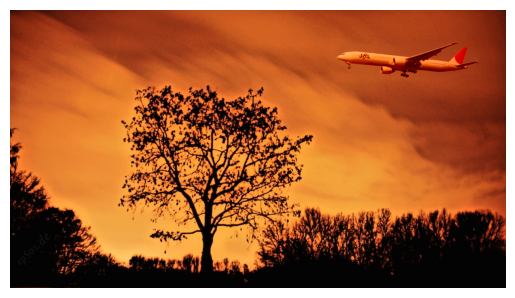

In [37]:
# Seamless Cloning
output = cv2.seamlessClone(src,img_sky,src_mask,center,cv2.NORMAL_CLONE)

# Bild anzeigen
plt.imshow(output)
plt.axis('off')
plt.show()

<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 1.10:</b><br>
  • Lesen Sie die Bilder <code>data/images/wood-texture.jpg</code> und <code>data/images/iloveyouticket.jpg</code> ein. <i>(Sie müssen diese nicht ausgeben.)</i><br>
  • Führen Sie zweimal ein Seamless Cloning entsprechend der Vorlesung mit <code>cv2</code> durch: Einmal mit Typ <code>cv2.NORMAL_CLONE</code> und einmal mit <code>cv2.MIXED_CLONE</code>. Geben Sie das Ergebnis im Notebook aus.
</div>
<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #66611F; 
    border-radius: 4px; 
    margin-top: 5px;
">
💡 <i><b>Hinweis:</b></i> Nutzen Sie für die Maske eine weiße Version des gesamten Bildes.
</div>

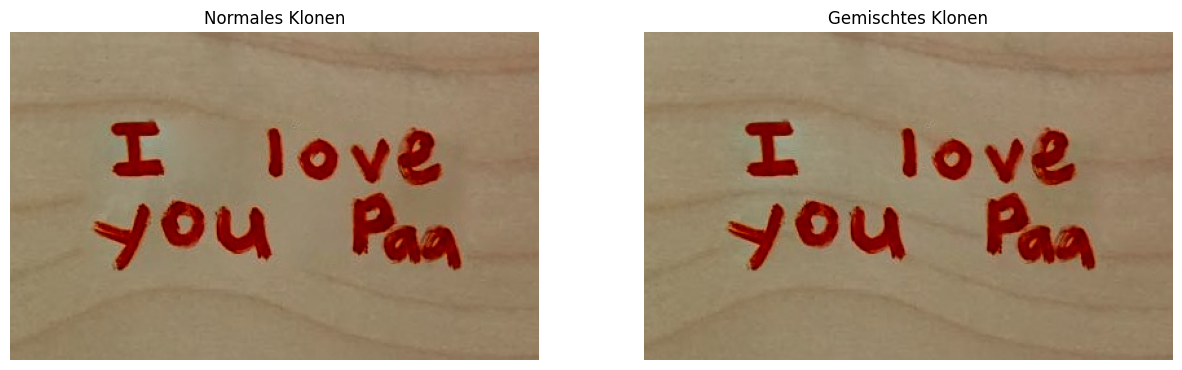

In [47]:
# Bilder einlesen
img_wood = cv2.imread("data/images/wood-texture.jpg")
img_ticket = cv2.imread("data/images/iloveyouticket.jpg")


# Maske: alles was nicht (annähernd) weiß ist
gray_ticket = cv2.cvtColor(img_ticket, cv2.COLOR_BGR2GRAY)
_, mask_gray = cv2.threshold(gray_ticket, 250, 255, cv2.THRESH_BINARY_INV)
mask = cv2.cvtColor(mask_gray, cv2.COLOR_GRAY2BGR)


# Die Schrift mittig auf das Brett setzen
center_point = (int(img_wood.shape[1]/2),int(img_wood.shape[0]/2))


# Seamless Cloning mit den zwei verschiedenen Typen
normal_clone = cv2.seamlessClone(img_ticket,img_wood,mask,center_point,cv2.NORMAL_CLONE)
mixed_clone = cv2.seamlessClone(img_ticket,img_wood,mask,center_point,cv2.MIXED_CLONE)

# Anzeigen
fig, axes = plt.subplots(1, 2, figsize=(15, 8))

axes[0].imshow(cv2.cvtColor(normal_clone, cv2.COLOR_BGR2RGB))
axes[0].axis('off')
axes[0].set_title('Normales Klonen')

axes[1].imshow(cv2.cvtColor(mixed_clone, cv2.COLOR_BGR2RGB))
axes[1].axis('off')
axes[1].set_title('Gemischtes Klonen')

plt.show()